# Chapitre 12 - Cours 3 : discriminants flexibles (FDA, PDA, MDA)

La seconde moitié du chapitre (sections 12.4 à 12.7) généralise l'analyse discriminante
linéaire (LDA, section 4.3) dans trois directions :

1. **FDA** (*flexible discriminant analysis*) : on réécrit la LDA comme une suite de
   **régressions** (*optimal scoring*), puis on remplace la régression linéaire par une
   régression non paramétrique ;
2. **PDA** (*penalized discriminant analysis*) : on **pénalise** les coefficients quand les
   variables sont nombreuses et corrélées (signaux, images) ;
3. **MDA** (*mixture discriminant analysis*) : chaque classe est un **mélange** de gaussiennes
   de covariance commune, estimé par l'algorithme EM.

Exemples : deux gaussiennes emboîtées (figure 12.9), la simulation « mixture »
(figure 12.13) et les données *waveform* (figures 12.14–12.15, tableau 12.4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (LDA, QDA, FDA, MDA, class_indicator, poly_basis, rbf_kernel,
                          second_diff_penalty, simulate_mixture, mixture_bayes_prob,
                          plot_mixture_boundary, waveform_h, simulate_waveform,
                          waveform_bayes_posterior)
set_style()

## 1. Pourquoi généraliser la LDA ?

La LDA est simple et souvent efficace, mais (section 12.4 du livre) :

* ses frontières sont **linéaires**, ce qui est parfois trop rigide ;
* un **seul prototype** (centroïde) par classe peut être insuffisant pour des classes
  hétérogènes ;
* avec **beaucoup de variables corrélées** (pixels, fréquences), elle estime trop de
  paramètres avec une grande variance.

Les trois réponses (FDA, PDA, MDA) reposent sur un même lien entre LDA et régression.

## 2. LDA et *optimal scoring*

Supposons $K$ classes $\mathcal G = \{1,\dots,K\}$. On cherche une fonction de **scores**
$\theta : \mathcal G\to\mathbb R$ telle que les étiquettes transformées $\theta(g_i)$ soient
le mieux possible prédites par une régression linéaire sur $x$ (éq. (12.52)) :

$$\min_{\beta,\theta}\sum_{i=1}^N\left(\theta(g_i) - x_i^T\beta\right)^2,$$

avec des contraintes sur $\theta$ (moyenne nulle, variance unité sur l'échantillon) pour
exclure la solution triviale $\theta = 0$, $\beta = 0$.

Plus généralement, on cherche $L \le K-1$ couples (scores $\theta_\ell$, coefficients
$\beta_\ell$) minimisant le **résidu quadratique moyen** (12.53)

$$\mathrm{ASR} = \frac1N\sum_{\ell=1}^L\sum_{i=1}^N\left(\theta_\ell(g_i) - x_i^T\beta_\ell\right)^2,$$

les scores étant orthonormés pour un produit scalaire convenable.

**Résultat (exercices 12.6 et 12.8).** Les $\beta_\ell$ sont proportionnels aux directions
discriminantes $\nu_\ell$ de la LDA (section 4.3.3), et la distance de Mahalanobis d'un point
$x$ au centroïde $\hat\mu_k$ s'écrit (12.54)–(12.55)

$$\delta_J(x, \hat\mu_k) = \sum_{\ell=1}^{K-1}w_\ell\left(\hat\eta_\ell(x) - \bar\eta_\ell^k\right)^2 + D(x),\qquad w_\ell = \frac{1}{r_\ell^2(1-r_\ell^2)},$$

où $\hat\eta_\ell(x) = x^T\beta_\ell$, $\bar\eta_\ell^k$ est sa moyenne dans la classe $k$,
$r_\ell^2$ le résidu quadratique moyen du $\ell$-ième ajustement, et $D(x)$ ne dépend pas de $k$.

> **À retenir.** La LDA = une suite de régressions linéaires + un classement au centroïde le
> plus proche dans l'espace des valeurs ajustées.

### 2.1 Algorithme (section 12.5.1)

Soit $Y$ la matrice indicatrice $N\times K$ ($y_{ik} = 1$ si $g_i = k$) et
$D_\pi = Y^TY/N$ la matrice diagonale des proportions de classes.

1. **Régression multivariée** : on régresse $Y$ sur $x$ (ou sur une base $h(x)$) ; on note
   $S$ l'opérateur linéaire de lissage, $\hat Y = SY$ et $\eta^*(x)$ les fonctions ajustées.
2. **Scores optimaux** : on diagonalise $Y^T\hat Y = Y^TSY$ avec la normalisation
   $\Theta^TD_\pi\Theta = I$ (problème aux valeurs propres généralisé
   $\frac1NY^TSY\theta = \alpha^2D_\pi\theta$).
3. **Mise à jour** : $\eta(x) = \Theta^T\eta^*(x)$. La première solution (constante,
   $\alpha^2 = 1$) est triviale ; les $K-1$ suivantes sont les fonctions discriminantes.

Ici $\alpha_\ell^2 = 1 - r_\ell^2$ est la part de variance des scores expliquée par la
régression. La classe `FDA` du module `esl.ch12_svm` implémente ces trois étapes.

### 2.2 Vérification : FDA avec régression linéaire = LDA

Sur les données *waveform* (3 classes, 21 variables), on compare les distances (12.54) de
la FDA aux distances de Mahalanobis exactes, calculées avec la covariance intra-classe
$W$ (normalisée par $N$). Leur différence doit être constante en $k$ : c'est le terme $D(x)$.

In [2]:
Xw, gw = datasets.load_waveform("train")
Xwt, gwt = datasets.load_waveform("test")
fda_lin = FDA().fit(Xw, gw)
lda = LDA().fit(Xw, gw)
N, K = len(gw), 3
W_N = lda.W_ * (N - K) / N
Wi = np.linalg.inv(W_N)
maha = np.column_stack([np.einsum("ij,jk,ik->i", Xwt - m, Wi, Xwt - m) for m in lda.means_])
diff = fda_lin.distances(Xwt) + 2 * np.log(fda_lin.priors_) - maha
print("variation de la différence entre classes (doit être ~0) : %.2e" % diff.std(axis=1).max())
print("alpha_l^2 =", fda_lin.eigvals_.round(4), "   poids w_l =", fda_lin.weights_.round(3))

variation de la différence entre classes (doit être ~0) : 9.01e-14
alpha_l^2 = [0.54   0.4394]    poids w_l = [4.026 4.06 ]


Et les coefficients $\beta_\ell$ de l'*optimal scoring* sont colinéaires aux directions
canoniques $\nu_\ell$ de la LDA (cosinus égal à $\pm1$) :

In [3]:
V, _ = lda.canonical_directions()
for l in range(2):
    b, v = fda_lin.beta_[1:, l], V[:, l]
    print("direction %d : cos(beta, nu) = %+.6f" % (l + 1, b @ v / np.linalg.norm(b) / np.linalg.norm(v)))
print("désaccord de classement FDA linéaire / LDA sur le test : %.3f"
      % np.mean(fda_lin.predict(Xwt) != lda.predict(Xwt)))

direction 1 : cos(beta, nu) = -1.000000
direction 2 : cos(beta, nu) = -1.000000
désaccord de classement FDA linéaire / LDA sur le test : 0.002


(Le très léger désaccord vient seulement de la normalisation de $W$ par $N$ ou par $N - K$,
qui change le poids relatif du terme $-2\log\hat\pi_k$.)

## 3. FDA : remplacer la régression linéaire

L'intérêt de la reformulation est de pouvoir remplacer $x^T\beta_\ell$ par des ajustements
**non paramétriques** $\eta_\ell(x)$ (modèles additifs, splines, MARS, noyaux…) en minimisant
(12.56) :

$$\mathrm{ASR}(\{\theta_\ell, \eta_\ell\}) = \frac1N\sum_{\ell=1}^L\left[\sum_{i=1}^N(\theta_\ell(g_i) - \eta_\ell(x_i))^2 + \lambda J(\eta_\ell)\right].$$

Si l'on régresse sur une base agrandie $h(x)$, la FDA est une LDA **dans l'espace agrandi** :
des frontières linéaires en $h(x)$ deviennent non linéaires en $x$ - exactement le paradigme
des SVM.

### 3.1 Deux gaussiennes emboîtées (figure 12.9)

50 points de $N(0, I)$ et 50 de $N(0, \frac94 I)$ dans $\mathbb R^2$. Avec une régression
polynomiale de degré 2, la FDA produit une frontière quadratique (une ellipse).

**Frontière de Bayes.** Pour $N(0,I)$ contre $N(0,cI)$ en dimension $p$ avec probabilités
égales, on compare les log-densités :
$-\frac{\|x\|^2}2 = -\frac{\|x\|^2}{2c} - \frac p2\log c$, soit
$\|x\|^2\left(1 - \frac1c\right) = p\log c$, c'est-à-dire le cercle
$\|x\| = \sqrt{\frac{p\,c\log c}{c-1}}$.

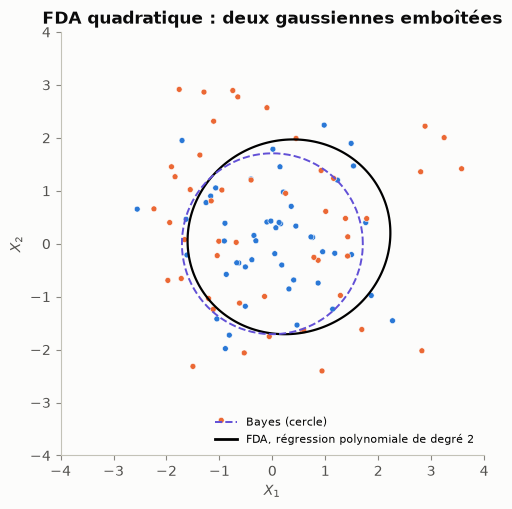

In [4]:
rng = np.random.RandomState(0)
c = 9 / 4
Xg = np.vstack([rng.randn(50, 2), np.sqrt(c) * rng.randn(50, 2)])
gg = np.r_[np.zeros(50, int), np.ones(50, int)]
fda_q = FDA(basis=lambda Z: poly_basis(Z, 2)).fit(Xg, gg)
xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
dist = fda_q.distances(np.c_[xx.ravel(), yy.ravel()])
Fq = (dist[:, 0] - dist[:, 1]).reshape(xx.shape)
r_bayes = np.sqrt(2 * c * np.log(c) / (c - 1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(Xg[:, 0], Xg[:, 1], c=gg, cmap=TWO_CLASS, s=18, edgecolor="white", lw=0.4)
ax.contour(xx, yy, Fq, levels=[0], colors="k", linewidths=1.6)
tt = np.linspace(0, 2 * np.pi, 200)
ax.plot(r_bayes * np.cos(tt), r_bayes * np.sin(tt), color=COLORS[6], ls="--", lw=1.4, label="Bayes (cercle)")
ax.plot([], [], color="k", label="FDA, régression polynomiale de degré 2")
ax.set_aspect("equal"); ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.grid(False)
ax.set_title("FDA quadratique : deux gaussiennes emboîtées")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### 3.2 FDA sur la simulation « mixture » (figure 12.13, en haut)

Le livre utilise MARS comme méthode de régression (chapitre 9). Pour rester dans l'esprit du
chapitre, nous utilisons ici une **régression ridge sur une base radiale**
$h_j(x) = \exp(-\gamma\|x - x_j\|^2)$ centrée aux points d'apprentissage ($\gamma = 1$,
$\lambda = 1$) - c'est la régression à noyau de la section 12.3.7. Avec $K=2$ classes, il n'y
a qu'une fonction discriminante.

In [5]:
mix = datasets.load_mixture_example()
Xm, gm = mix["x"], mix["y"]
rng = np.random.RandomState(0)
Xmt, gmt = simulate_mixture(5000, mix["means"], rng)
bayes_mix = np.mean((mixture_bayes_prob(Xmt, mix["means"]) > 0.5) != gmt)
fda_rbf = FDA(basis=lambda Z: rbf_kernel(Z, Xm, 1.0), lam=1.0).fit(Xm, gm)
mda_mix = MDA(n_sub=5, n_iter=100, rng=np.random.RandomState(0)).fit(Xm, gm)
for name, mod in [("FDA / base radiale", fda_rbf), ("MDA, 5 sous-classes", mda_mix)]:
    print("%-20s : erreur app. %.3f, test %.3f" % (name, np.mean(mod.predict(Xm) != gm), np.mean(mod.predict(Xmt) != gmt)))
print("erreur de Bayes      : %.3f" % bayes_mix)

FDA / base radiale   : erreur app. 0.155, test 0.217
MDA, 5 sous-classes  : erreur app. 0.160, test 0.218
erreur de Bayes      : 0.210


## 4. MDA : des mélanges de gaussiennes par classe

La LDA est un classifieur par **prototypes** : un centroïde par classe. La MDA (section 12.7)
en autorise plusieurs : la densité de la classe $k$ est un mélange (12.59)

$$P(X\mid G=k) = \sum_{r=1}^{R_k}\pi_{kr}\,\phi(X;\mu_{kr},\Sigma),\qquad \sum_r\pi_{kr} = 1,$$

où $\phi(\cdot;\mu,\Sigma)$ est la densité gaussienne et **la même** covariance $\Sigma$ sert
partout. Par la formule de Bayes, avec les probabilités a priori $\Pi_k$ (12.60) :

$$P(G=k\mid X=x) = \frac{\sum_{r}\pi_{kr}\phi(x;\mu_{kr},\Sigma)\Pi_k}{\sum_{\ell=1}^K\sum_r\pi_{\ell r}\phi(x;\mu_{\ell r},\Sigma)\Pi_\ell}.$$

**Estimation : l'algorithme EM.** Maximiser directement la log-vraisemblance (12.61)
$\sum_k\sum_{g_i=k}\log\left[\sum_r\pi_{kr}\phi(x_i;\mu_{kr},\Sigma)\Pi_k\right]$ est malcommode
(un logarithme de somme). L'algorithme EM (chapitre 8) alterne deux étapes simples :

* **étape E** : pour chaque $x_i$ de la classe $k$, on calcule la **responsabilité** de chaque
  sous-classe (12.62) :
  $W(c_{kr}\mid x_i, g_i) = \dfrac{\pi_{kr}\phi(x_i;\mu_{kr},\Sigma)}{\sum_{\ell}\pi_{k\ell}\phi(x_i;\mu_{k\ell},\Sigma)}$ ;
* **étape M** : on ré-estime $\pi_{kr}$, $\mu_{kr}$ (moyennes pondérées par les
  responsabilités) et $\Sigma$ (covariance intra-sous-classes pondérée).

Chaque itération fait **croître** la log-vraisemblance. L'initialisation se fait par des
$k$-moyennes dans chaque classe (poids 0/1).

Sur la simulation « mixture », avec 5 sous-classes par classe (figure 12.13, en bas) :

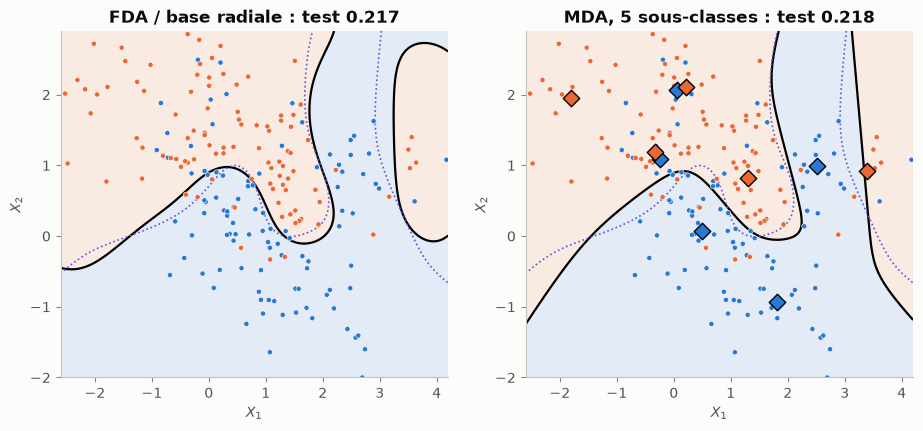

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_mixture_boundary(axes[0], Xm, gm, lambda Z: fda_rbf.distances(Z)[:, 0] - fda_rbf.distances(Z)[:, 1],
                      mix["means"], title="FDA / base radiale : test %.3f" % np.mean(fda_rbf.predict(Xmt) != gmt))
plot_mixture_boundary(axes[1], Xm, gm, lambda Z: mda_mix.predict_proba(Z)[:, 1] - 0.5,
                      mix["means"], title="MDA, 5 sous-classes : test %.3f" % np.mean(mda_mix.predict(Xmt) != gmt))
for k, col in [(0, BLUE), (1, ORANGE)]:
    axes[1].scatter(mda_mix.mus_[k, :, 0], mda_mix.mus_[k, :, 1], marker="D", s=70, color=col,
                    edgecolor="k", zorder=6)
plt.show()

Les losanges sont les centres $\hat\mu_{kr}$ des sous-classes. Comme dans le livre, la MDA
est proche de l'optimum de Bayes : sa structure (mélange de gaussiennes de même covariance)
est celle du modèle générateur.

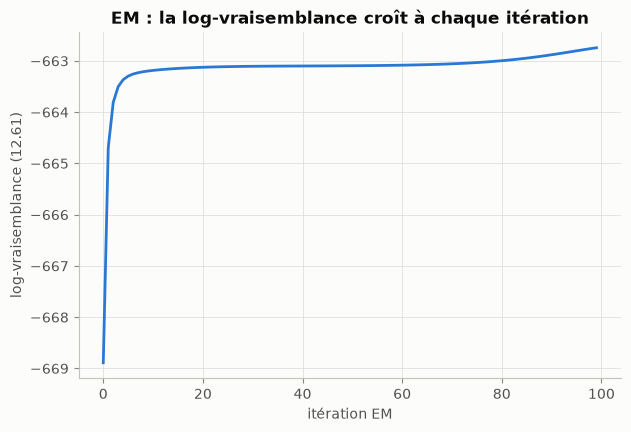

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(mda_mix.loglik_, color=BLUE)
ax.set_xlabel("itération EM"); ax.set_ylabel("log-vraisemblance (12.61)")
ax.set_title("EM : la log-vraisemblance croît à chaque itération")
plt.show()

**Lien avec l'optimal scoring.** L'étape M est une LDA pondérée avec $R = \sum_kR_k$
« classes ». Le livre montre qu'elle se résout par *optimal scoring* en remplaçant la matrice
indicatrice $Y$ par une matrice de réponse **floue** $Z$ (12.63), dont la ligne $i$ contient
les responsabilités $W(c_{kr}\mid x_i,g_i)$ dans les colonnes de la classe $g_i$ et des zéros
ailleurs. On peut ainsi utiliser une FDA ou une PDA à l'étape M. Voici les six lignes de $Z$
les plus « floues » pour la MDA sur *waveform* (3 classes $\times$ 3 sous-classes) ; la
plupart des autres lignes sont presque des indicatrices, car les sous-classes sont bien
séparées.

In [8]:
mda_w = MDA(n_sub=3, n_iter=50, rng=np.random.RandomState(0)).fit(Xw, gw)
lj = mda_w._log_joint(Xw)
Yw, _ = class_indicator(gw)
lj = np.where(Yw[:, :, None] == 1, lj, -np.inf)
Zb = np.exp(lj - lj.max(axis=(1, 2), keepdims=True))
Zb = (Zb / Zb.sum(axis=(1, 2), keepdims=True)).reshape(len(gw), 9)
import pandas as pd
idx = np.argsort(Zb.max(1))[:6]
pd.DataFrame(Zb[idx].round(2), index=["i = %d, g = %d" % (i, gw[i]) for i in idx],
             columns=["c%d%d" % (k, r) for k in range(1, 4) for r in range(1, 4)])

,c11,c12,c13,c21,c22,c23,c31,c32,c33
"i = 118, g = 2",0.00,0.00,0.0,0.50,0.5,0.00,0.00,0.00,0.0
"i = 243, g = 2",0.00,0.00,0.0,0.48,0.0,0.52,0.00,0.00,0.0
"i = 248, g = 1",0.54,0.46,0.0,0.00,0.0,0.00,0.00,0.00,0.0
"i = 112, g = 2",0.00,0.00,0.0,0.78,0.0,0.22,0.00,0.00,0.0
"i = 195, g = 2",0.00,0.00,0.0,0.78,0.0,0.22,0.00,0.00,0.0
"i = 253, g = 3",0.00,0.00,0.0,0.00,0.0,0.00,0.19,0.81,0.0


## 5. PDA : pénaliser les coefficients

Si la régression de la FDA est une régression sur une base $h(x)$ avec pénalité quadratique,
le critère devient (12.57)

$$\mathrm{ASR}(\{\theta_\ell,\beta_\ell\}) = \frac1N\sum_{\ell=1}^L\left[\sum_{i=1}^N(\theta_\ell(g_i) - h(x_i)^T\beta_\ell)^2 + \lambda\beta_\ell^T\Omega\beta_\ell\right],$$

et l'on montre (exercice 12.7) que cela revient à une LDA **pénalisée** dans l'espace des
$h(x)$ : distance $D(x,\mu) = (h(x)-h(\mu))^T(\Sigma_W + \lambda\Omega)^{-1}(h(x)-h(\mu))$
(12.58) et directions discriminantes maximisant $u^T\Sigma_{\text{Bet}}u$ sous
$u^T(\Sigma_W + \lambda\Omega)u = 1$.

Pour des signaux, inutile d'agrandir la base ($h(x) = x$) : on choisit $\Omega$ pour que
$\beta^T\Omega\beta$ mesure la **rugosité** de $\beta$ vu comme une fonction de l'indice de la
variable. Ici, avec les différences secondes,
$\beta^T\Omega\beta = \sum_j(\beta_{j+1} - 2\beta_j + \beta_{j-1})^2$.

> **Intuition.** Deux variables voisines très corrélées peuvent recevoir en LDA des
> coefficients énormes et de signes opposés qui se compensent : c'est du bruit. La pénalité
> impose des coefficients qui varient régulièrement.

Les 21 variables de *waveform* sont ordonnées (ce sont des instants) : comparons les
coefficients discriminants de la LDA et de la PDA (dans l'esprit de la figure 12.11).

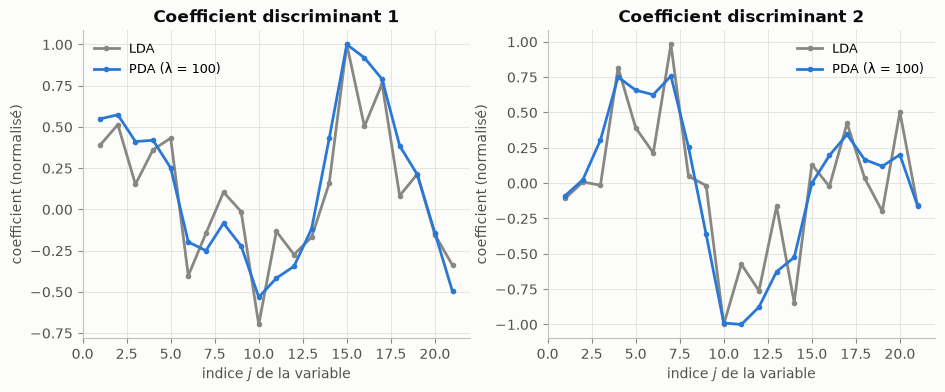

In [9]:
Om = second_diff_penalty(21)
pda = FDA(lam=100.0, Omega=Om).fit(Xw, gw)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for l, ax in enumerate(axes):
    for mod, name, col in [(fda_lin, "LDA", GRAY), (pda, "PDA (λ = 100)", BLUE)]:
        b = mod.beta_[1:, l]
        ax.plot(np.arange(1, 22), b / np.abs(b).max(), marker="o", ms=3, color=col, label=name)
    ax.set_xlabel("indice $j$ de la variable"); ax.set_ylabel("coefficient (normalisé)")
    ax.set_title("Coefficient discriminant %d" % (l + 1))
    ax.legend()
plt.show()

Erreur test en fonction de $\lambda$ : une pénalisation modérée améliore la LDA ($\lambda = 0$).

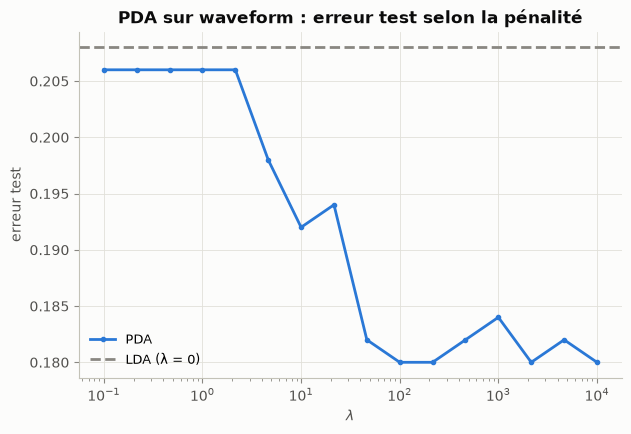

In [10]:
lams = np.r_[0, np.logspace(-1, 4, 16)]
err_pda = [np.mean(FDA(lam=l, Omega=Om).fit(Xw, gw).predict(Xwt) != gwt) for l in lams]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(lams[1:], err_pda[1:], marker="o", ms=3, color=BLUE, label="PDA")
ax.axhline(err_pda[0], color=GRAY, ls="--", label="LDA (λ = 0)")
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel("erreur test")
ax.set_title("PDA sur waveform : erreur test selon la pénalité")
ax.legend()
plt.show()

## 6. Les données *waveform*

Problème à 3 classes et 21 variables (Breiman et al., 1984), défini par (12.64) :

$$\begin{aligned}
\text{classe 1 :}\quad X_j &= Uh_1(j) + (1-U)h_2(j) + \varepsilon_j,\\
\text{classe 2 :}\quad X_j &= Uh_1(j) + (1-U)h_3(j) + \varepsilon_j,\\
\text{classe 3 :}\quad X_j &= Uh_2(j) + (1-U)h_3(j) + \varepsilon_j,
\end{aligned}$$

avec $j = 1,\dots,21$, $U\sim\mathcal U(0,1)$, $\varepsilon_j\sim N(0,1)$ indépendants, et les
formes triangulaires $h_1(j) = \max(6 - |j - 11|, 0)$, $h_2(j) = h_1(j-4)$, $h_3(j) = h_1(j+4)$.

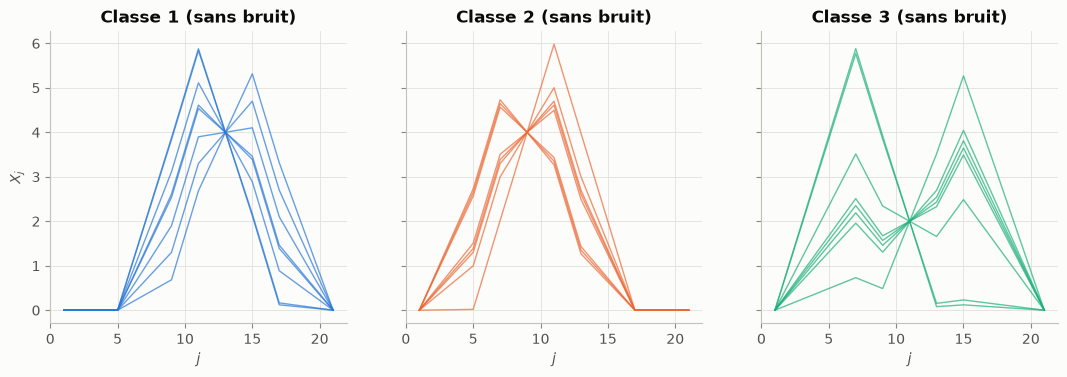

In [11]:
h = waveform_h()
rng = np.random.RandomState(0)
Xclean, gclean = simulate_waveform(60, rng, noise=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for k, ax in enumerate(axes):
    for x_ in Xclean[gclean == k + 1][:8]:
        ax.plot(np.arange(1, 22), x_, color=COLORS[k], lw=1, alpha=0.7)
    ax.set_title("Classe %d (sans bruit)" % (k + 1))
    ax.set_xlabel("$j$")
axes[0].set_ylabel("$X_j$")
plt.show()

Comme on connaît le modèle, on peut calculer la règle de **Bayes** : la densité de la classe 1
est $\int_0^1\phi(x; uh_1 + (1-u)h_2, I)\,du$ (intégrale en $u$ calculée numériquement).
Le livre cite une erreur de Bayes d'environ 0,14.

In [12]:
rng = np.random.RandomState(1)
Xbig, gbig = simulate_waveform(20000, rng)
print("erreur de Bayes estimée (20 000 tirages) : %.3f" % np.mean(waveform_bayes_posterior(Xbig).argmax(1) + 1 != gbig))

erreur de Bayes estimée (20 000 tirages) : 0.134


## 7. Tableau 12.4 (version simplifiée)

On reproduit l'expérience du livre sur 10 simulations (300 observations d'apprentissage,
500 de test). Faute de MARS et de CART dans ce chapitre, on remplace les lignes FDA/MARS par
une **FDA sur la base polynomiale de degré 2** (253 fonctions, ridge $\lambda = 1000$), et la
MDA pénalisée « 4 ddl » par une MDA dont la covariance est régularisée
($\Sigma + \Omega$, avec $\Omega$ la matrice de rugosité). Les autres méthodes sont fidèles.

In [13]:
methods = {
    "LDA": lambda: LDA(),
    "QDA": lambda: QDA(),
    "FDA / polynôme deg. 2 (ridge)": lambda: FDA(basis=lambda Z: poly_basis(Z, 2), lam=1000.0),
    "PDA (λ = 100)": lambda: FDA(lam=100.0, Omega=Om),
    "MDA (3 sous-classes)": lambda: MDA(3, n_iter=50, rng=np.random.RandomState(0)),
    "MDA (3 sous-classes, régularisée)": lambda: MDA(3, n_iter=50, shrink=1.0, Omega=Om, rng=np.random.RandomState(0)),
}
rng = np.random.RandomState(2)
res = {name: [] for name in methods}
res["Bayes"] = []
for sim in range(10):
    Xa, ga = simulate_waveform(300, rng)
    Xb, gb = simulate_waveform(500, rng)
    for name, make in methods.items():
        mod = make().fit(Xa, ga)
        res[name].append((np.mean(mod.predict(Xa) != ga), np.mean(mod.predict(Xb) != gb)))
    res["Bayes"].append((np.nan, np.mean(waveform_bayes_posterior(Xb).argmax(1) + 1 != gb)))

In [14]:
rows = []
for name, v in res.items():
    v = np.array(v)
    cells = []
    for col in v.T:
        cells.append("-" if np.isnan(col).all() else "%.3f (%.3f)" % (col.mean(), col.std(ddof=1) / np.sqrt(len(col))))
    rows.append([name] + cells)
pd.DataFrame(rows, columns=["méthode", "erreur apprentissage", "erreur test"]).set_index("méthode")

,erreur apprentissage,erreur test
méthode,,
LDA,0.122 (0.005),0.200 (0.006)
QDA,0.043 (0.002),0.212 (0.005)
FDA / polynôme deg. 2 (ridge),0.053 (0.003),0.163 (0.007)
PDA (λ = 100),0.124 (0.005),0.171 (0.007)
MDA (3 sous-classes),0.094 (0.004),0.183 (0.005)
"MDA (3 sous-classes, régularisée)",0.111 (0.004),0.154 (0.007)
Bayes,-,0.131 (0.005)


On retrouve les conclusions du livre : la QDA sur-apprend (erreur d'apprentissage très
faible, test médiocre) ; la pénalisation (PDA) améliore nettement la LDA ; la MDA, dont la
structure imite le modèle générateur, améliore la LDA, et sa version régularisée est la
meilleure méthode du tableau, la plus proche de l'erreur de Bayes (comme la MDA pénalisée du
livre). La FDA polynomiale pénalisée fait ici aussi très bien : la pénalisation compte autant
que la flexibilité.